# Cross-validation and SHAP explanations

These cells were executed against the real project outputs. The complete training
and SQL implementation is in the linked source modules. This walkthrough reads and
verifies executed artifacts rather than silently retraining the expensive models.
Home Credit is a consumer-lending proxy; validation is random holdout, never true OOT.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'reports/metrics.json').exists():
    ROOT=ROOT.parent
metrics=json.loads((ROOT/'reports/metrics.json').read_text())


## Training-only tuning

,candidate,fold,auc,num_leaves,min_child_samples,reg_lambda,n_estimators
0,0,0,0.776428,15,150,2.0,300
1,0,1,0.776964,15,150,2.0,300
2,0,2,0.775140,15,150,2.0,300
3,1,0,0.776812,31,150,2.0,300
4,1,1,0.776761,31,150,2.0,300
5,1,2,0.774601,31,150,2.0,300
6,2,0,0.777137,15,300,5.0,500
7,2,1,0.777985,15,300,5.0,500
8,2,2,0.775235,15,300,5.0,500
9,3,0,0.777009,31,300,5.0,500


,mean,std
candidate,,
0,0.776177,0.000938
1,0.776058,0.001262
2,0.776786,0.001408
3,0.775787,0.001216


,Unnamed: 0,mean_abs_shap_log_odds
0,EXT_SOURCE_2,0.307207
1,EXT_SOURCE_3,0.268701
2,EXT_SOURCE_1,0.142689
3,credit_goods_ratio,0.127012
4,credit_annuity_ratio,0.095049
5,ORGANIZATION_TYPE,0.094325
6,OCCUPATION_TYPE,0.083781
7,previous_credit_application_ratio,0.083324
8,installment_recent_late_share,0.083281
9,DAYS_EMPLOYED,0.082723


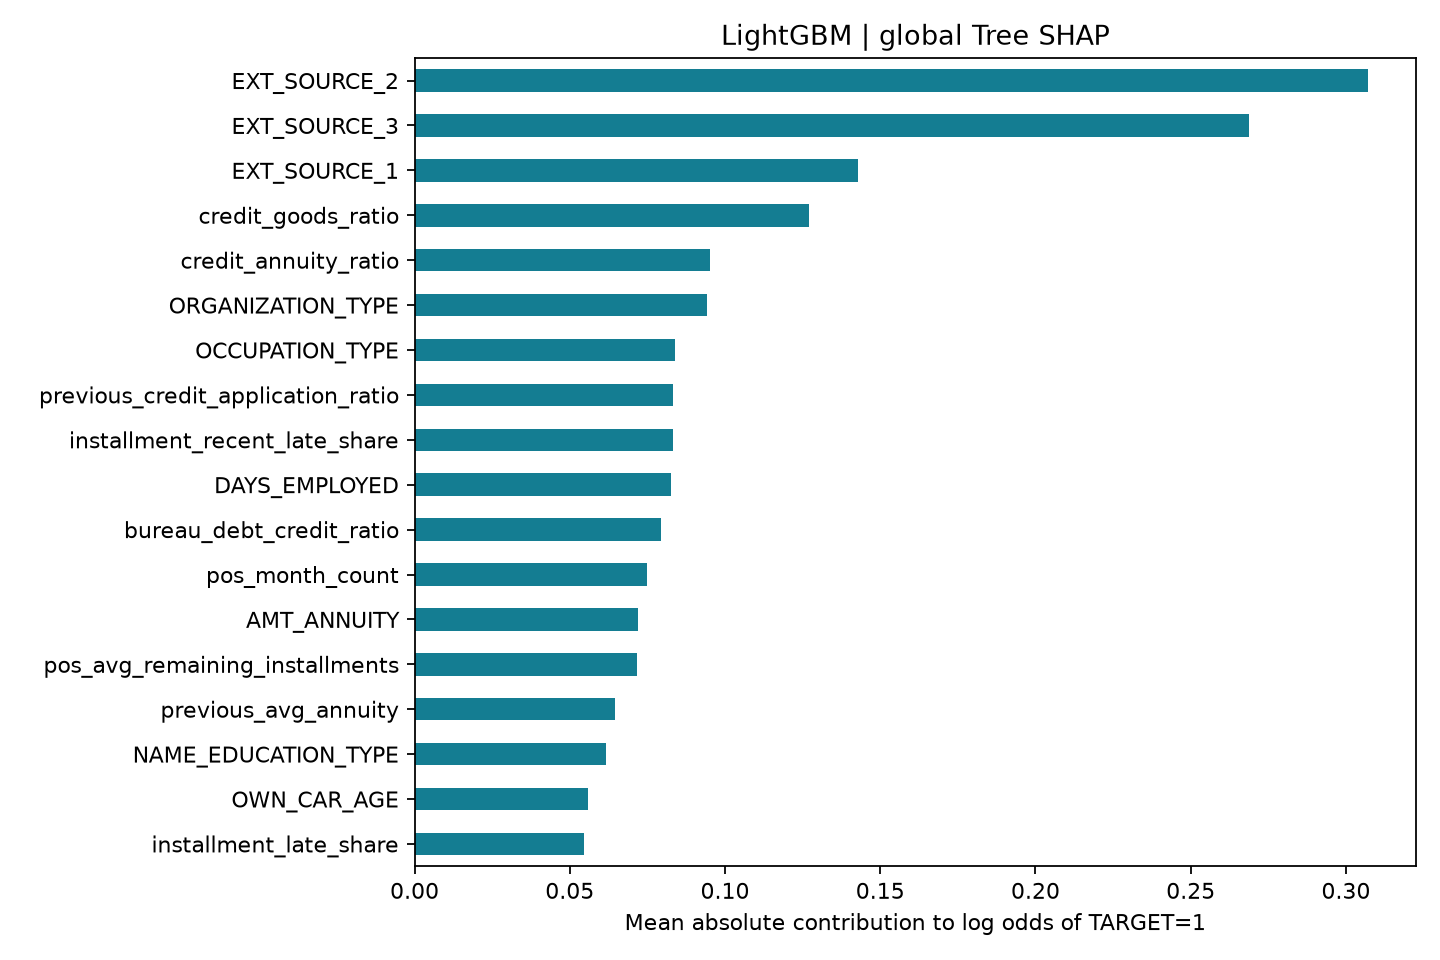

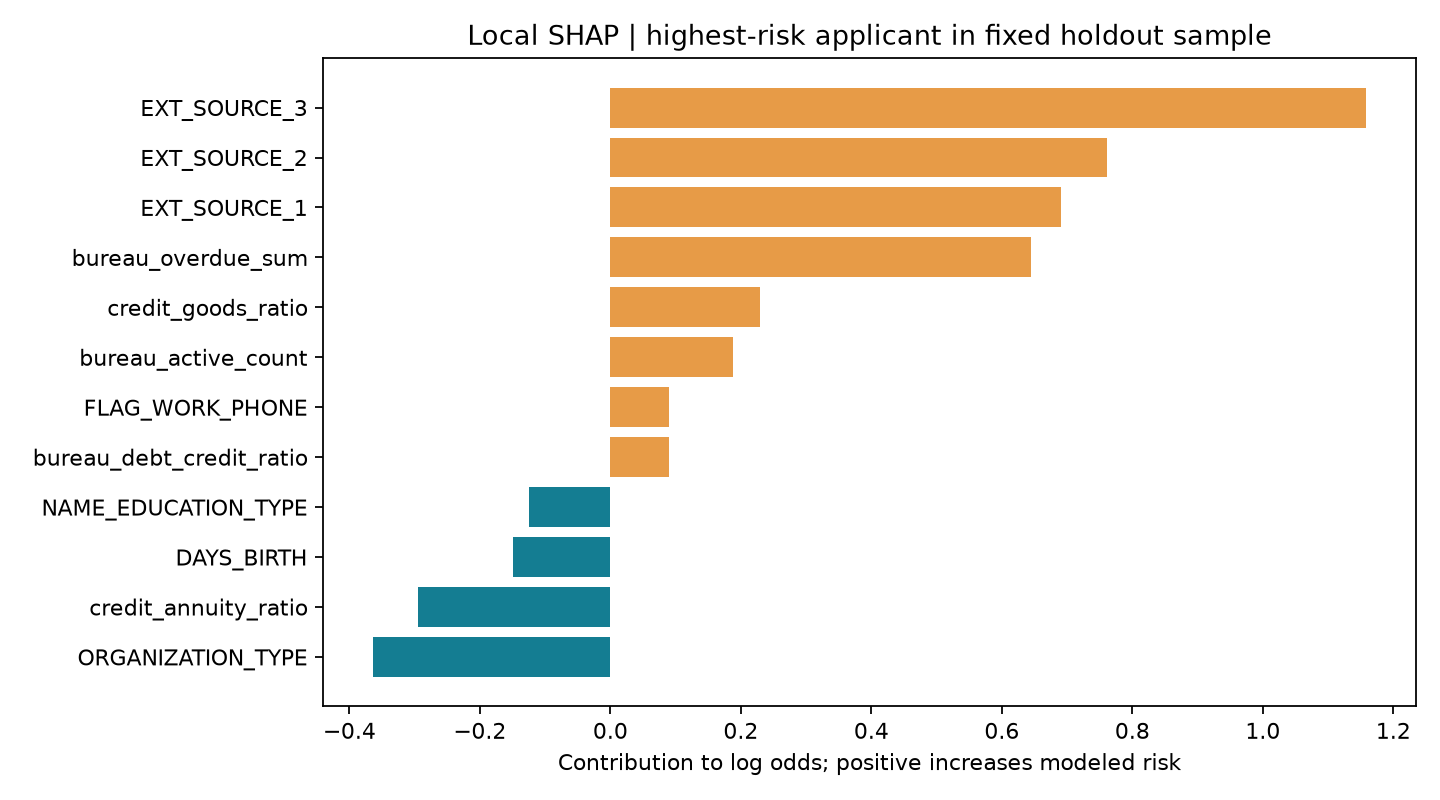

In [2]:
cv=pd.read_csv(ROOT/'reports/boosting_cv.csv')
display(cv)
display(cv.groupby('candidate').auc.agg(['mean','std']))
display(pd.read_csv(ROOT/'reports/shap_global.csv').head(20))
display(Image(filename=str(ROOT/'reports/figures/shap_global.png')))
display(Image(filename=str(ROOT/'reports/figures/shap_local.png')))

## Interpretation

See src/models.py. Category mappings are fitted separately inside each CV fold.
Tree-path-dependent SHAP explains log odds; positive local contributions increase modeled
risk. Attributions can be shared among correlated features and do not imply causality.
No holdout performance selected the candidate settings.